In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Load Dataset

In [ ]:
df = pd.read_csv("heart.csv")
print("Dataset berhasil dibaca.\n")
print(df.head())

Dataset berhasil dibaca.

   Age Sex ChestPainType  RestingBP  Cholesterol  FastingBS RestingECG  MaxHR  \
0   40   M           ATA        140          289          0     Normal    172   
1   49   F           NAP        160          180          0     Normal    156   
2   37   M           ATA        130          283          0         ST     98   
3   48   F           ASY        138          214          0     Normal    108   
4   54   M           NAP        150          195          0     Normal    122   

  ExerciseAngina  Oldpeak ST_Slope  HeartDisease  
0              N      0.0       Up             0  
1              N      1.0     Flat             1  
2              N      0.0       Up             0  
3              Y      1.5     Flat             1  
4              N      0.0       Up             0  


# Tahap EDA

In [6]:
# EDA sederhana
print("Rangkuman informasi dataset.")
df.info()

print("\nStatistik deskriptif.")
print(df.describe())

print(f"\nJumlah data (baris, kolom) : {df.shape}")

Rangkuman informasi dataset.
<class 'pandas.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    str    
 2   ChestPainType   918 non-null    str    
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    str    
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    str    
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    str    
 11  HeartDisease    918 non-null    int64  
dtypes: float64(1), int64(6), str(5)
memory usage: 86.2 KB

Statistik deskriptif.
              Age   RestingBP  Cholesterol   FastingBS       MaxHR  \
count  918.000000  918.000000   918.000000  918.000000  918.000000   
mean    53.510893  132.39

In [8]:
# Cek Missing Values
df.isnull().sum()

Age               0
Sex               0
ChestPainType     0
RestingBP         0
Cholesterol       0
FastingBS         0
RestingECG        0
MaxHR             0
ExerciseAngina    0
Oldpeak           0
ST_Slope          0
HeartDisease      0
dtype: int64

<function matplotlib.pyplot.show(close=None, block=None)>

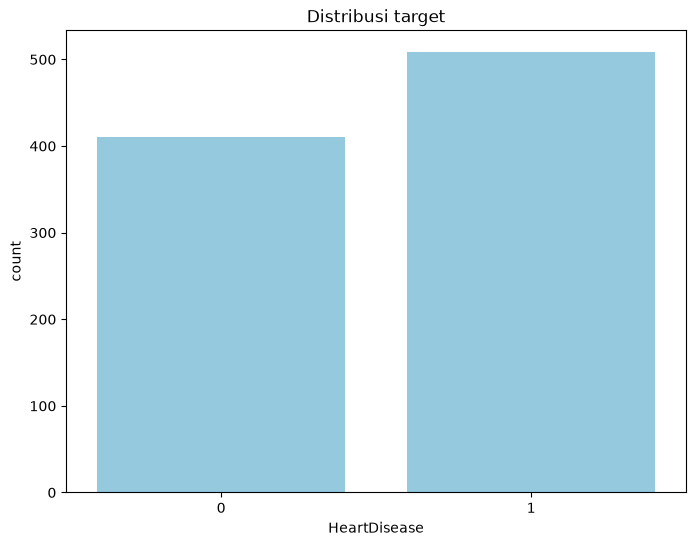

In [27]:
# Visualisasi distribusi target
plt.figure(figsize=(8,6))
sns.countplot(x='HeartDisease', data=df, color='skyblue')
plt.title("Distribusi target")
plt.show

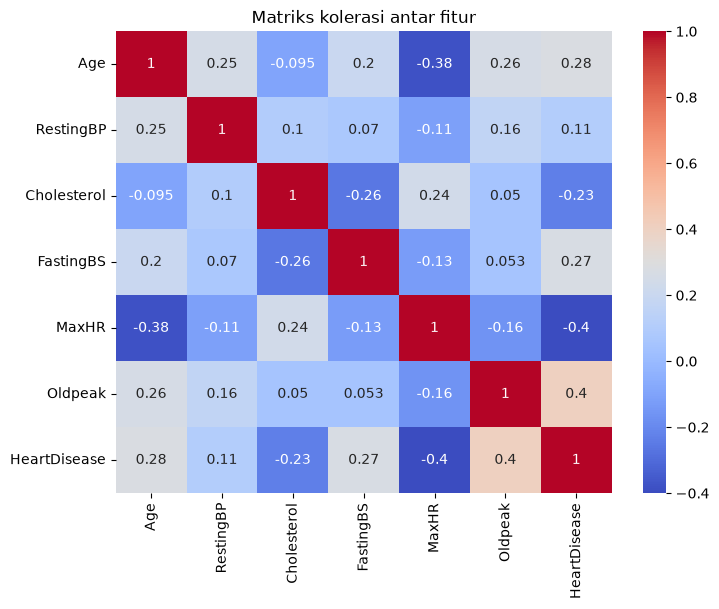

In [12]:
# Analisis korelasi menggunakan heatmap untuk melihat fitur mana yang paling berpengaruh
plt.figure(figsize=(8,6))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap="coolwarm")
plt.title("Matriks kolerasi antar fitur")
plt.show()

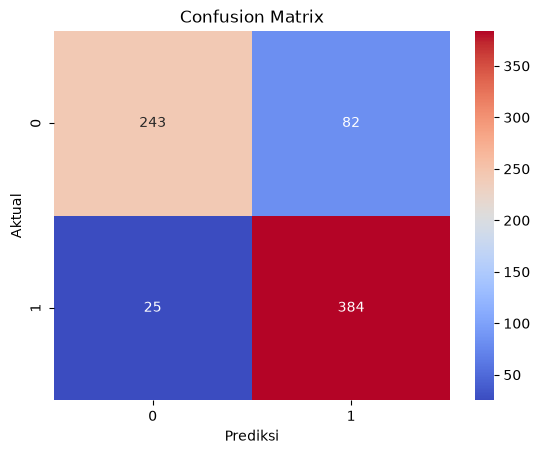

In [24]:
# Menampilkan Confusion Matrix
cm = confusion_matrix(y_train, clf.predict(X_train))
sns.heatmap(cm, annot=True, cmap='coolwarm',xticklabels=clf.classes_, yticklabels=clf.classes_, fmt='d')
plt.xlabel('Prediksi')
plt.ylabel('Aktual')
plt.title('Confusion Matrix')
plt.show()

# Preprocessing & Modelling

In [20]:
# Feature selection
X = df.drop(columns=['HeartDisease'])
y = df['HeartDisease']

# Melakukan one hot encoding
X = pd.get_dummies(X, drop_first=True)
print(X.head())

   Age  RestingBP  Cholesterol  FastingBS  MaxHR  Oldpeak  Sex_M  \
0   40        140          289          0    172      0.0   True   
1   49        160          180          0    156      1.0  False   
2   37        130          283          0     98      0.0   True   
3   48        138          214          0    108      1.5  False   
4   54        150          195          0    122      0.0   True   

   ChestPainType_ATA  ChestPainType_NAP  ChestPainType_TA  RestingECG_Normal  \
0               True              False             False               True   
1              False               True             False               True   
2               True              False             False              False   
3              False              False             False               True   
4              False               True             False               True   

   RestingECG_ST  ExerciseAngina_Y  ST_Slope_Flat  ST_Slope_Up  
0          False             False          F

In [16]:
# Membagi data menjadi data latih dan uji
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=67
)

print(f"Jumlah data latih : {len(X_train)}")
print(f"Jumlah data uji : {len(X_test)}")

Jumlah data latih : 734
Jumlah data uji : 184


In [17]:
# Membuat model 
clf = DecisionTreeClassifier(max_depth=4, random_state=42)

# Training
clf.fit(X_train, y_train)

# Prediksi
y_pred = clf.predict(X_test)

In [19]:
# Evaluasi akurasi
akurasi = accuracy_score(y_test, y_pred)
print(f"Akurasi model : {akurasi * 100:.2f}%")

print("\nClassification Reoprt")
print(classification_report(y_test, y_pred))

Akurasi model : 85.87%

Classification Reoprt
              precision    recall  f1-score   support

           0       0.88      0.80      0.84        85
           1       0.84      0.91      0.87        99

    accuracy                           0.86       184
   macro avg       0.86      0.85      0.86       184
weighted avg       0.86      0.86      0.86       184



# Visualisasi Decision Tree

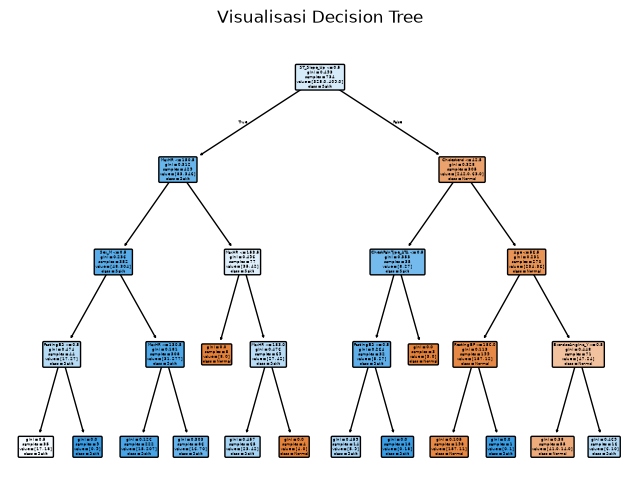

In [21]:
plt.figure(figsize=(8,6))
plot_tree(clf, feature_names=X.columns, class_names=['Normal', 'Sakit'], filled=True, rounded=True)
plt.title("Visualisasi Decision Tree")
plt.show()